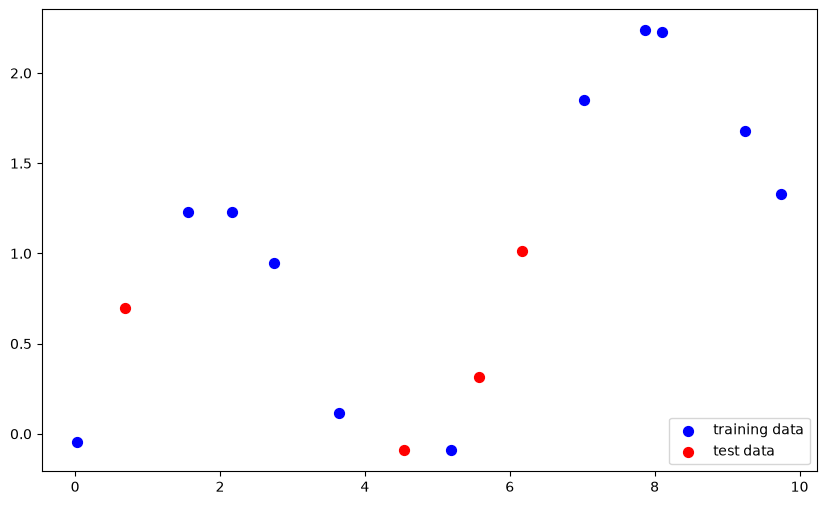

In [161]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(seed=0)
n = 15
x = np.linspace(0,10,n) + rng.standard_normal(n)/5
y = np.sin(x)+x/6 + rng.standard_normal(n)/10

X_train, X_test, y_train, y_test = train_test_split(x, y, random_state=0)

fig, ax = plt.subplots(figsize=(10,6))
ax.scatter(X_train, y_train, label='training data', c='blue', s=50)
ax.scatter(X_test, y_test, label='test data', c='red', s=50)
ax.legend(loc=4)

### Polynomial Features
Question 1

Write a function that fits a polynomial LinearRegression model on the training data X_train for degrees 1, 3, 6, and 9. (Use PolynomialFeatures in sklearn.preprocessing to create the polynomial features and then fit a linear regression model) For each model, find 100 predicted values over the interval x = 0 to 10 (e.g. np.linspace(0,10,100)) and store this in a numpy array. The first row of this array should correspond to the output from the model trained on degree 1, the second row degree 3, the third row degree 6, and the fourth row degree 9.

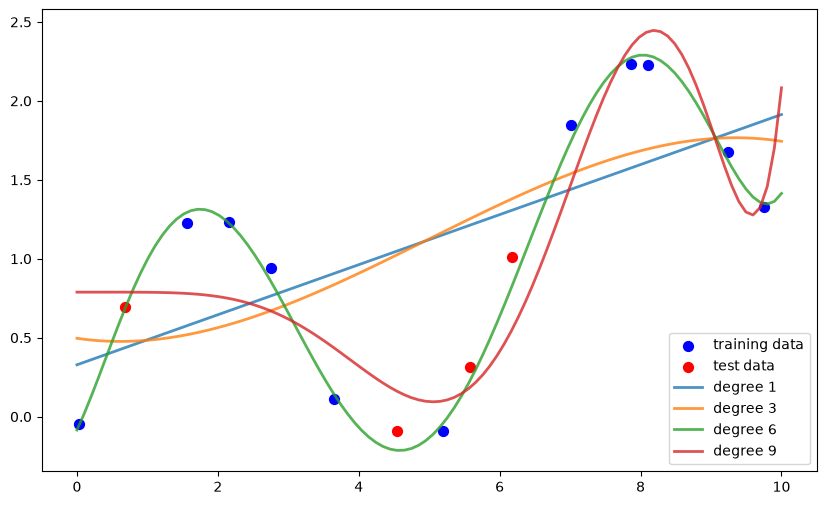

In [162]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

degrees = [1, 3, 6, 9]

# samples to test model
X_sample = np.linspace(0,10,100)

# store predictions, 4 degrees x 100 target values
predictions = np.zeros((4, 100))

for i, deg in enumerate(degrees):
    # set transformer
    poly = PolynomialFeatures(degree=deg, include_bias=False)
    
    # fit and transform test data and fit model
    X_tr_poly = poly.fit_transform(X_train.reshape(-1,1))
    model = LinearRegression().fit(X_tr_poly, y_train)

    # test model predictions
    X_sample_poly = poly.transform(X_sample.reshape(-1,1))
    y_pred = model.predict(X_sample_poly)

    # update prdictions with y_pred
    predictions[i] = y_pred


# plot prediction boundary
for i, deg in enumerate(degrees):
    ax.plot(X_sample, predictions[i], alpha=0.8, lw=2, label=f'degree {deg}')
ax.legend(loc=4)
display(fig)

Question 2

Write a function that fits a polynomial LinearRegression model on the training data X_train for degrees 0 through 9. For each model compute the  𝑅2
  (coefficient of determination) regression score on the training data as well as the the test data, and return both of these arrays in a tuple.

This function should return a tuple of numpy arrays (r2_train, r2_test). Both arrays should have shape (10,)

In [215]:
from sklearn.metrics import r2_score

degrees = list(range(10))

# store R2 
r2_train = np.zeros(10)
r2_test = np.zeros(10)

for i, deg in enumerate(degrees):
   # set transformer
    poly = PolynomialFeatures(degree=deg)
    
    # fit, transform and train model
    X_tr_poly = poly.fit_transform(X_train.reshape(-1,1))
    model = LinearRegression().fit(X_tr_poly, y_train)

    # transform test data
    X_ts_poly = poly.transform(X_test.reshape(-1,1))

    # predict target value for training and test data
    y_tr_pred = model.predict(X_tr_poly)
    y_ts_pred = model.predict(X_ts_poly)
    
    # compute R2 regeression score
    r2_train[i] = r2_score(y_train, y_tr_pred)
    r2_test[i] = r2_score(y_test, y_ts_pred)

print(r2_train)
print(r2_test)

best_degree = int(np.argmax(r2_test))
print(f'The best degree is {best_degree} with R2 = {r2_test[best_degree]:.2f}')

[0.         0.39487178 0.39503076 0.40742846 0.94084207 0.95246138
 0.99540876 0.75499876 0.79666038 0.78407433]
[-2.64274214 -2.30895877 -2.21193565 -2.38241693  0.68839495  0.5089755
  0.91715555  0.80398521  0.76781073  0.55943086]
The best degree is 6 with R2 = 0.92


Question 3

Based on the  $𝑅^2$ scores from question 2 (degree levels 0 through 9), what degree level corresponds to a model that is underfitting? What degree level corresponds to a model that is overfitting? What choice of degree level would provide a model with good generalization performance on this dataset?

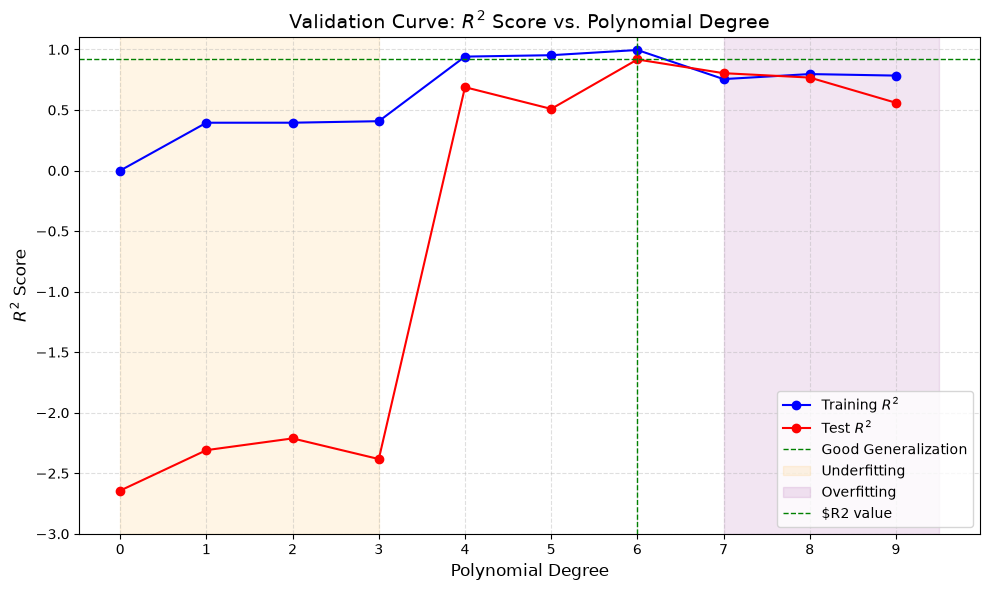

In [219]:
# # assign underfitting, overfitting and good generalization
# underfitting = int
# best_degree = int(np.argmax(r2_test))

fig3, ax3 = plt.subplots(figsize=(10,6))

# plot lines
ax3.plot(degrees, r2_train, marker='o', color='blue', label='Training $R^2$')
ax3.plot(degrees, r2_test, marker='o', color='red', label='Test $R^2$')
ax3.grid(True, alpha=0.4, linestyle='--')

ax3.axvline(x=best_degree, linestyle='--', color='green', lw=1, label='Good Generalization')
ax3.axvspan(0,3, alpha=0.1, color='orange', label='Underfitting')
ax3.axvspan(7,9.5, alpha=0.1, color='purple', label='Overfitting')
ax3.axhline(y=r2_test[best_degree], linestyle='--', color='green', lw=1, label='$R2 value')

# customize chart
ax3.set_xticks(degrees)
ax3.set_ylim(-3, 1.1)
ax3.set_xlabel('Polynomial Degree', fontsize=12)
ax3.set_ylabel('$R^2$ Score', fontsize=12)
ax3.set_title('Validation Curve: $R^2$ Score vs. Polynomial Degree', fontsize=14)
ax3.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

from the graph:
1. underfitting degrees are 0 - 3
2. overfitting degrees are 7 - 9
3. good generalization degree is 6 with $R^2$ value of approx 0.92

In [225]:
print(r2_train)
print(r2_test)

list(zip(r2_train, r2_test))

[0.         0.39487178 0.39503076 0.40742846 0.94084207 0.95246138
 0.99540876 0.75499876 0.79666038 0.78407433]
[-2.64274214 -2.30895877 -2.21193565 -2.38241693  0.68839495  0.5089755
  0.91715555  0.80398521  0.76781073  0.55943086]


[(np.float64(0.0), np.float64(-2.6427421415430428)),
 (np.float64(0.39487178089897956), np.float64(-2.3089587726000826)),
 (np.float64(0.3950307643246952), np.float64(-2.211935654901693)),
 (np.float64(0.40742846203312155), np.float64(-2.3824169283440115)),
 (np.float64(0.940842065345521), np.float64(0.6883949473229498)),
 (np.float64(0.9524613805344988), np.float64(0.508975496973888)),
 (np.float64(0.9954087561669436), np.float64(0.9171555487402689)),
 (np.float64(0.7549987561387929), np.float64(0.8039852050873859)),
 (np.float64(0.7966603788292165), np.float64(0.7678107252100862)),
 (np.float64(0.7840743321668876), np.float64(0.5594308574976083))]

## Lasso Regularized vs Linear Non Regularized

Question 4

Training models on high degree polynomial features can result in overfitting. Train two models: a non-regularized LinearRegression model and a Lasso Regression model (with parameters alpha=0.01, max_iter=10000, tol=0.1) on polynomial features of degree 12. Return the  $𝑅^2$ score for LinearRegression and Lasso model's test sets.

In [260]:
from sklearn.linear_model import Lasso

X_tr = X_train.reshape(-1,1)
X_ts = X_test.reshape(-1,1)

# create polynomial transformer (degree=12)
poly = PolynomialFeatures(degree=12, include_bias=False)

# fit and transform data
X_tr_poly = poly.fit_transform(X_tr)
X_ts_poly = poly.transform(X_ts)

# train models
lin_model = LinearRegression().fit(X_tr_poly, y_train)
reg_model = Lasso(alpha=0.01, max_iter=10000, tol=0.1).fit(X_tr_poly, y_train)

# predict target values
y_lin_pred = lin_model.predict(X_ts_poly)
y_reg_pred = reg_model.predict(X_ts_poly)

r2_lin = r2_score(y_test, y_lin_pred)
r2_reg = r2_score(y_test, y_reg_pred)
print (r2_lin, '\n', r2_reg)

-0.11955568688284646 
 0.543912054534874


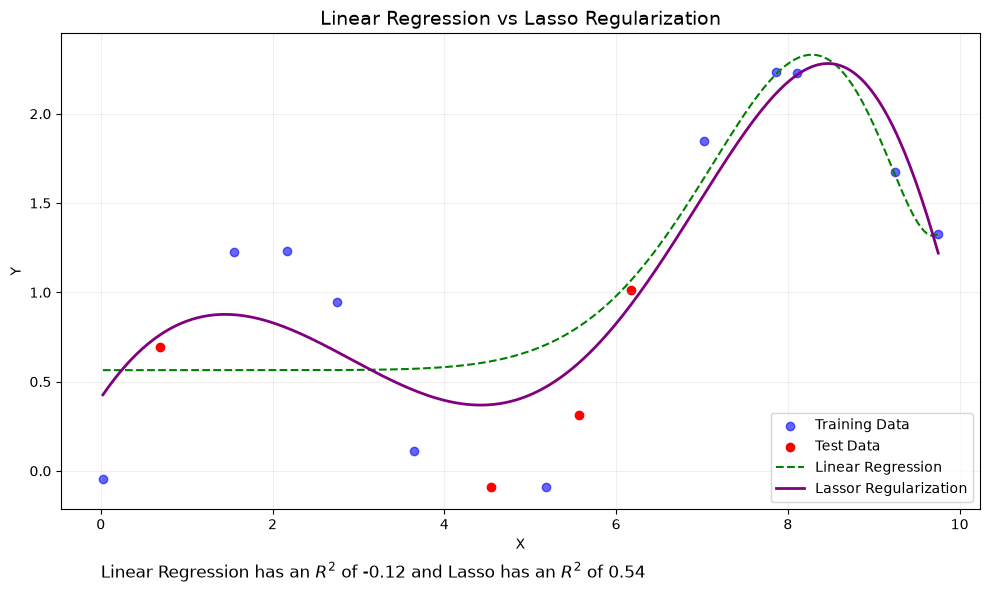

In [267]:
# plot graph

# create 300 point range for X_train
X4 = np.linspace(X_train.min(), X_train.max(), 300)
X4_poly = poly.transform(X4.reshape(-1,1))

# predict target values using trained models
y4_lin_pred = lin_model.predict(X4_poly)
y4_reg_pred = reg_model.predict(X4_poly)


fig4, ax4 = plt.subplots(figsize=(10,6))
ax4.scatter(X_train, y_train, color='blue', alpha=0.6, label='Training Data')
ax4.scatter(X_test, y_test, color='red', label='Test Data')

# plot model prediction
ax4.plot(X4, y4_lin_pred, label='Linear Regression', color='green', linestyle='--')
ax4.plot(X4, y4_reg_pred, label='Lassor Regularization', color='purple', lw=2)

# customize chart
ax4.grid(True, alpha=0.2)
ax4.legend(loc='lower right')
ax4.set_title('Linear Regression vs Lasso Regularization', fontsize=14)
ax4.set_xlabel('X')
ax4.set_ylabel('Y')

# add caption to graph
ax4.text(0, -.6,
         f'Linear Regression has an $R^2$ of {r2_lin:.2f} and Lasso has an $R^2$ of {r2_reg:.2f}',
         fontsize=12,
        )

plt.tight_layout()
plt.show()